In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("../Data/India_Elec_data_(Jan2020-Mar2025).csv")

# Display first 5 rows
df.head()

,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage
0,2020-01-01 00:00:00,Andhra Pradesh,8561.0,0.0,170.1,66.3,-0.5,367.0,0.0
1,2020-01-01 00:00:00,Arunachal Pradesh,109.0,1.0,2.2,1.9,0.2,34.0,0.0
2,2020-01-01 00:00:00,Assam,1358.0,28.0,23.4,17.3,1.3,90.0,0.2
3,2020-01-01 00:00:00,Bihar,4656.0,0.0,82.0,81.2,-0.7,255.0,0.0
4,2020-01-01 00:00:00,Chandigarh,306.0,0.0,4.9,4.7,0.2,46.0,0.0


In [63]:
# Dataset information
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Shape: (69012, 9)

Columns:
['Date', 'State', 'Max Demand Met', 'Shortage During Peak', 'Energy Met', 'Drawl Schedule', 'OD(+) / UD(-)', 'Max OD', 'Energy Shortage']

Data types:
Date                     object
State                    object
Max Demand Met          float64
Shortage During Peak    float64
Energy Met              float64
Drawl Schedule          float64
OD(+) / UD(-)           float64
Max OD                  float64
Energy Shortage         float64
dtype: object


In [64]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Check date range
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check number of states
print("\nNumber of states:", df["State"].nunique())

# List states
print("\nStates:")
print(df["State"].unique())

Start Date: 2020-01-01 00:00:00
End Date: 2025-03-31 00:00:00

Missing values:
Date                       0
State                      0
Max Demand Met          6040
Shortage During Peak    5006
Energy Met              4998
Drawl Schedule          4988
OD(+) / UD(-)           4988
Max OD                  4992
Energy Shortage         4988
dtype: int64

Number of states: 36

States:
['Andhra Pradesh' 'Arunachal Pradesh' 'Assam' 'Bihar' 'Chandigarh'
 'Chhattisgarh' 'DD' 'DNH' 'DVC' 'Delhi' 'ER Odisha' 'Essar steel' 'Goa'
 'Gujarat' 'HP' 'Haryana' 'J&K(UT) & Ladakh(UT)' 'Jharkhand' 'Kerala' 'MP'
 'Manipur' 'Mizoram' 'NER Meghalaya' 'NR UP' 'Nagaland' 'Puducherry'
 'Punjab' 'Rajasthan' 'SR Karnataka' 'Sikkim' 'Tamil Nadu' 'Telangana'
 'Tripura' 'Uttarakhand' 'WR Maharashtra' 'West Bengal']


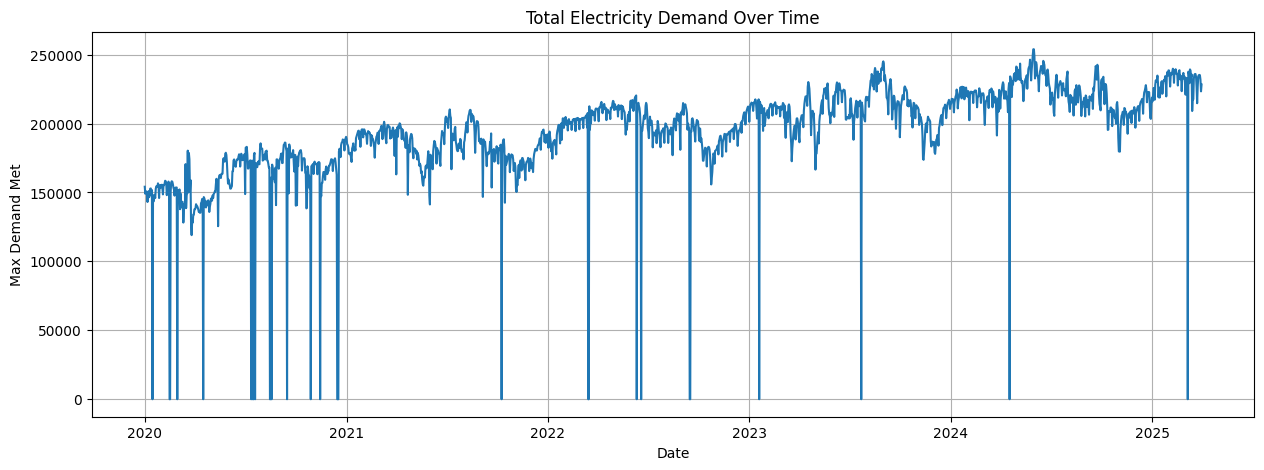

In [65]:
# Overall demand over time

daily_demand = df.groupby("Date")["Max Demand Met"].sum()

plt.figure(figsize=(15, 5))
plt.plot(daily_demand)
plt.title("Total Electricity Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Max Demand Met")
plt.grid(True)
plt.show()

In [66]:
# Check missing demand values by date

missing_demand = df[df["Max Demand Met"].isna()]

print("Total missing demand rows:", len(missing_demand))

print("\nMissing demand by year:")
print(missing_demand.groupby(missing_demand["Date"].dt.year).size())

print("\nMissing demand by state:")
print(missing_demand["State"].value_counts())

Total missing demand rows: 6040

Missing demand by year:
Date
2020    1237
2021     438
2022    1001
2023    1475
2024    1496
2025     393
dtype: int64

Missing demand by state:
State
Essar steel             1816
DD                      1056
DNH                     1056
Jharkhand                796
J&K(UT) & Ladakh(UT)     126
ER Odisha                111
WR Maharashtra           107
Puducherry               100
Andhra Pradesh            43
Arunachal Pradesh         43
Tamil Nadu                43
West Bengal               43
SR Karnataka              32
Chhattisgarh              30
Chandigarh                29
DVC                       29
Goa                       29
Bihar                     29
Delhi                     29
Assam                     29
Haryana                   29
HP                        29
Gujarat                   29
Kerala                    29
NER Meghalaya             29
MP                        29
Manipur                   29
Mizoram                   29
Pun

In [67]:
# Number of missing demand values on each date

missing_by_date = (
    df.groupby("Date")["Max Demand Met"]
      .apply(lambda x: x.isna().sum())
)

print("Maximum missing states on a single date:",
      missing_by_date.max())

print("\nDates with the most missing values:")
print(missing_by_date.sort_values(ascending=False).head(20))

Maximum missing states on a single date: 36

Dates with the most missing values:
Date
2020-12-17    36
2022-03-16    36
2022-03-15    36
2023-01-19    36
2022-09-16    36
2020-09-15    36
2020-08-16    36
2020-10-28    36
2020-01-15    36
2022-06-19    36
2022-06-11    36
2020-02-15    36
2020-07-16    36
2020-07-19    36
2020-07-12    36
2020-04-16    36
2020-07-15    36
2020-11-14    36
2020-02-16    36
2020-08-18    36
Name: Max Demand Met, dtype: int64


In [68]:
# Check how many complete dates we have

total_states = df["State"].nunique()

complete_dates = (missing_by_date == 0).sum()
incomplete_dates = (missing_by_date > 0).sum()

print("Total dates:", len(missing_by_date))
print("Complete dates:", complete_dates)
print("Incomplete dates:", incomplete_dates)

Total dates: 1917
Complete dates: 23
Incomplete dates: 1894


In [69]:
# Check number of records per date

records_per_date = df.groupby("Date").size()

print("Records per date:")
print(records_per_date.value_counts().sort_index())

print("\nExpected records per date:", df["State"].nunique())

Records per date:
36    1917
Name: count, dtype: int64

Expected records per date: 36


In [70]:
# Check the number of unique dates for each state

dates_per_state = df.groupby("State")["Date"].nunique()

print(dates_per_state.sort_values())

State
Andhra Pradesh          1917
Arunachal Pradesh       1917
Assam                   1917
Bihar                   1917
Chandigarh              1917
Chhattisgarh            1917
DD                      1917
DNH                     1917
DVC                     1917
Delhi                   1917
ER Odisha               1917
Essar steel             1917
Goa                     1917
Gujarat                 1917
HP                      1917
Haryana                 1917
J&K(UT) & Ladakh(UT)    1917
Jharkhand               1917
Kerala                  1917
MP                      1917
Manipur                 1917
Mizoram                 1917
NER Meghalaya           1917
NR UP                   1917
Nagaland                1917
Puducherry              1917
Punjab                  1917
Rajasthan               1917
SR Karnataka            1917
Sikkim                  1917
Tamil Nadu              1917
Telangana               1917
Tripura                 1917
Uttarakhand             1917
WR Mahar

## Preprocessing Strategy

**Findings from EDA:**
- 6,040 missing `Max Demand Met` values across 36 states.
- ~29 dates have ALL 36 states missing (fully-blank dates).
- `Essar steel` (1,816 missing), `DD` (1,056), `DNH` (1,056), `Jharkhand` (796) have structural sparsity — large contiguous gaps.
- Most other states have exactly 29 missing values (the fully-blank dates).

**Strategy:**
1. **State-wise time-based linear interpolation** — each state's series is interpolated independently using its own nearest valid neighbours. This handles both partial-missing dates and fully-blank dates.
2. For states with very long contiguous gaps (no valid neighbours on one side), interpolation cannot reliably fill values — those remain NaN and are flagged.
3. No values are invented; no future data leaks into the historical series.

In [71]:
# ── Preprocessing: state-wise time-based interpolation ──────────────────────

# Work on a copy so the original df is never modified
demand_df = df[["Date", "State", "Max Demand Met"]].copy()

# Identify fully-blank dates (all 36 states NaN) and check for consecutive runs
missing_by_date = demand_df.groupby("Date")["Max Demand Met"].apply(lambda x: x.isna().sum())
fully_blank_dates = missing_by_date[missing_by_date == 36].index.sort_values()

print(f"Fully-blank dates (all 36 states NaN): {len(fully_blank_dates)}")

# Check for consecutive runs among fully-blank dates
if len(fully_blank_dates) > 0:
    gaps = (fully_blank_dates.to_series().diff().dt.days.fillna(1) != 1)
    run_ids = gaps.cumsum()
    runs = run_ids.value_counts().sort_index()
    max_consecutive = runs.max()
    print(f"Max consecutive fully-blank dates: {max_consecutive}")
    print(f"Number of separate blank-date runs: {len(runs)}")

# ── State-wise interpolation ─────────────────────────────────────────────────
# Set Date as index per state, interpolate, then reset
def interpolate_state(group):
    """Linear time-based interpolation for a single state's demand series."""
    group = group.set_index("Date").sort_index()
    group["Max Demand Met"] = (
        group["Max Demand Met"]
        .interpolate(method="time", limit_direction="both")
    )
    return group.reset_index()

demand_df = (
    demand_df
    .groupby("State", group_keys=False)
    .apply(interpolate_state)
)

# ── Summary ──────────────────────────────────────────────────────────────────
remaining_missing = demand_df["Max Demand Met"].isna().sum()

print("\n── Cleaned DataFrame Summary ──")
print(f"Original shape : {df.shape}")
print(f"Cleaned shape  : {demand_df.shape}")
print(f"Remaining NaN  : {remaining_missing}")
print(f"Dates          : {demand_df['Date'].nunique()}")
print(f"States         : {demand_df['State'].nunique()}")
print(f"Date range     : {demand_df['Date'].min().date()} → {demand_df['Date'].max().date()}")

# Flag states that still have NaN after interpolation
if remaining_missing > 0:
    still_missing = (
        demand_df[demand_df["Max Demand Met"].isna()]
        ["State"].value_counts()
    )
    print("\nStates with remaining NaN (insufficient valid neighbours):")
    print(still_missing)

Fully-blank dates (all 36 states NaN): 29
Max consecutive fully-blank dates: 3
Number of separate blank-date runs: 22

── Cleaned DataFrame Summary ──
Original shape : (69012, 9)
Cleaned shape  : (69012, 3)
Remaining NaN  : 0
Dates          : 1917
States         : 36
Date range     : 2020-01-01 → 2025-03-31


C:\Users\shrey\AppData\Local\Temp\ipykernel_11476\3026736523.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(interpolate_state)


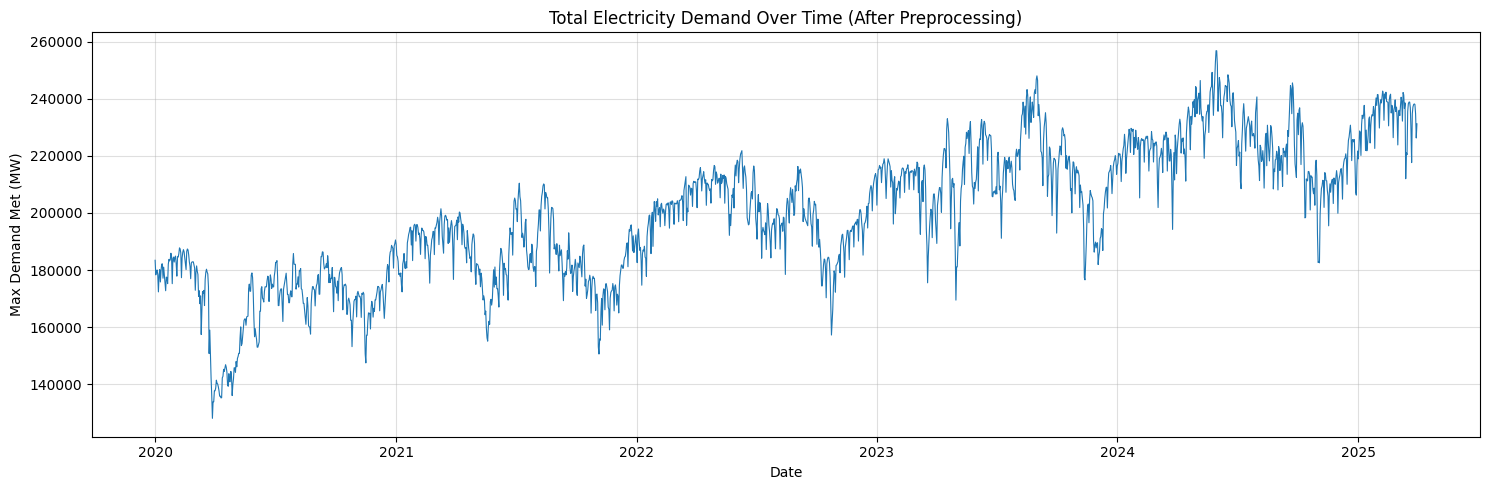

In [72]:
# ── Daily total demand series & plot ─────────────────────────────────────────

# Sum across all states per date (NaN states are excluded from sum automatically)
daily_demand = demand_df.groupby("Date")["Max Demand Met"].sum()

plt.figure(figsize=(15, 5))
plt.plot(daily_demand, linewidth=0.8)
plt.title("Total Electricity Demand Over Time (After Preprocessing)")
plt.xlabel("Date")
plt.ylabel("Max Demand Met (MW)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# Create daily total demand
daily_demand = demand_df.groupby("Date")["Max Demand Met"].sum()

# Convert to DataFrame
forecast_df = daily_demand.reset_index()
forecast_df.columns = ["Date", "Demand"]

# Sort chronologically
forecast_df = forecast_df.sort_values("Date").reset_index(drop=True)

# -------------------------
# Time features
# -------------------------
forecast_df["year"] = forecast_df["Date"].dt.year
forecast_df["month"] = forecast_df["Date"].dt.month
forecast_df["day"] = forecast_df["Date"].dt.day
forecast_df["day_of_week"] = forecast_df["Date"].dt.dayofweek
forecast_df["day_of_year"] = forecast_df["Date"].dt.dayofyear
forecast_df["week_of_year"] = (
    forecast_df["Date"].dt.isocalendar().week.astype(int)
)

# -------------------------
# Lag features
# -------------------------
forecast_df["lag_1"] = forecast_df["Demand"].shift(1)
forecast_df["lag_7"] = forecast_df["Demand"].shift(7)
forecast_df["lag_14"] = forecast_df["Demand"].shift(14)
forecast_df["lag_30"] = forecast_df["Demand"].shift(30)

# -------------------------
# Rolling features
# shift(1) prevents leakage
# -------------------------
past_demand = forecast_df["Demand"].shift(1)

forecast_df["rolling_mean_7"] = past_demand.rolling(7).mean()
forecast_df["rolling_mean_14"] = past_demand.rolling(14).mean()
forecast_df["rolling_mean_30"] = past_demand.rolling(30).mean()

# Remove initial rows without enough historical data
forecast_df = forecast_df.dropna().reset_index(drop=True)

# Verification
print("Shape:", forecast_df.shape)

print("\nColumns:")
print(forecast_df.columns.tolist())

print("\nMissing values:")
print(forecast_df.isnull().sum())

print("\nFirst 5 rows:")
display(forecast_df.head())

print("\nLast 5 rows:")
display(forecast_df.tail())

Shape: (1887, 15)

Columns:
['Date', 'Demand', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_14', 'rolling_mean_30']

Missing values:
Date               0
Demand             0
year               0
month              0
day                0
day_of_week        0
day_of_year        0
week_of_year       0
lag_1              0
lag_7              0
lag_14             0
lag_30             0
rolling_mean_7     0
rolling_mean_14    0
rolling_mean_30    0
dtype: int64

First 5 rows:


,Date,Demand,year,month,day,day_of_week,day_of_year,week_of_year,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,2020-01-31,184490.0,2020,1,31,4,31,5,182816.0,183679.0,172776.0,183430.0,182973.000000,180900.714286,179840.650000
1,2020-02-01,184898.0,2020,2,1,5,32,5,184490.0,185900.0,177559.0,178320.0,183088.857143,181737.428571,179875.983333
2,2020-02-02,182243.0,2020,2,2,6,33,5,184898.0,184615.0,177212.0,179547.0,182945.714286,182261.642857,180095.250000
3,2020-02-03,177883.0,2020,2,3,0,34,6,182243.0,175245.0,175250.0,180038.0,182606.857143,182621.000000,180185.116667
4,2020-02-04,184654.0,2020,2,4,1,35,6,177883.0,184006.0,182053.0,178447.0,182983.714286,182809.071429,180113.283333



Last 5 rows:


,Date,Demand,year,month,day,day_of_week,day_of_year,week_of_year,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
1882,2025-03-27,238178.0,2025,3,27,3,86,13,237958.0,238827.0,238532.0,237007.0,233181.642857,231208.607143,233918.133333
1883,2025-03-28,237967.0,2025,3,28,4,87,13,238178.0,236806.0,211990.0,239610.0,233088.928571,231183.321429,233957.166667
1884,2025-03-29,234696.0,2025,3,29,5,88,13,237967.0,229126.0,221108.0,235510.0,233254.785714,233038.821429,233902.400000
1885,2025-03-30,226246.0,2025,3,30,6,89,13,234696.0,217637.0,220419.0,237051.0,234050.500000,234009.392857,233875.266667
1886,2025-03-31,231218.0,2025,3,31,0,90,14,226246.0,234780.5,235531.0,233117.0,235280.357143,234425.607143,233515.100000


In [74]:
# -------------------------
# Time-based Train/Test Split
# -------------------------

# Use the last 20% of the data for testing
split_index = int(len(forecast_df) * 0.80)

train_df = forecast_df.iloc[:split_index].copy()
test_df = forecast_df.iloc[split_index:].copy()

print("Training data:")
print("Start:", train_df["Date"].min())
print("End:", train_df["Date"].max())
print("Rows:", len(train_df))

print("\nTesting data:")
print("Start:", test_df["Date"].min())
print("End:", test_df["Date"].max())
print("Rows:", len(test_df))

Training data:
Start: 2020-01-31 00:00:00
End: 2024-03-18 00:00:00
Rows: 1509

Testing data:
Start: 2024-03-19 00:00:00
End: 2025-03-31 00:00:00
Rows: 378


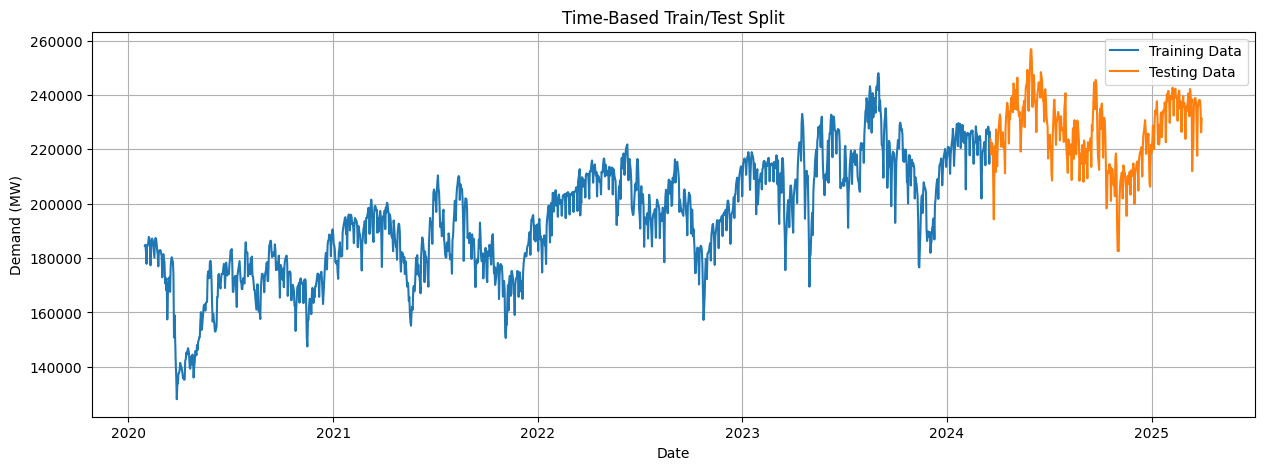

In [75]:
# Visualize the train/test split

plt.figure(figsize=(15, 5))

plt.plot(
    train_df["Date"],
    train_df["Demand"],
    label="Training Data"
)

plt.plot(
    test_df["Date"],
    test_df["Demand"],
    label="Testing Data"
)

plt.title("Time-Based Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True)
plt.show()

In [76]:
# -------------------------
# Prepare features and target
# -------------------------

# Features used for prediction
features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30"
]

X_train = train_df[features]
y_train = train_df["Demand"]

X_test = test_df[features]
y_test = test_df["Demand"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1509, 13)
y_train shape: (1509,)
X_test shape: (378, 13)
y_test shape: (378,)


In [77]:
import numpy as np
print("NumPy version:", np.__version__)

NumPy version: 2.2.6


In [78]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [79]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../Data/India_Elec_data_(Jan2020-Mar2025).csv"

df = pd.read_csv(file_path)

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of states:", df["State"].nunique())

Dataset shape: (69012, 9)
Date range: 2020-01-01 00:00:00 to 2025-03-31 00:00:00
Number of states: 36


In [81]:
# Keep only the columns needed for demand forecasting
demand_df = df[["Date", "State", "Max Demand Met"]].copy()

# Make sure demand is numeric
demand_df["Max Demand Met"] = pd.to_numeric(
    demand_df["Max Demand Met"],
    errors="coerce"
)

# Sort by state and date
demand_df = demand_df.sort_values(["State", "Date"])

# Interpolate missing demand values separately for each state
demand_df["Max Demand Met"] = (
    demand_df.groupby("State")["Max Demand Met"]
    .transform(lambda x: x.interpolate(method="linear", limit_direction="both"))
)

print("Cleaned demand data shape:", demand_df.shape)
print("Remaining missing values:", demand_df["Max Demand Met"].isna().sum())
print("Number of states:", demand_df["State"].nunique())

Cleaned demand data shape: (69012, 3)
Remaining missing values: 0
Number of states: 36


In [82]:
daily_demand = (
    demand_df
    .groupby("Date")["Max Demand Met"]
    .sum()
    .reset_index()
)

daily_demand.columns = ["Date", "Demand"]

daily_demand = daily_demand.sort_values("Date").reset_index(drop=True)

print("Daily demand shape:", daily_demand.shape)
print("Date range:", daily_demand["Date"].min(), "to", daily_demand["Date"].max())

print("\nFirst 5 rows:")
print(daily_demand.head())

Daily demand shape: (1917, 2)
Date range: 2020-01-01 00:00:00 to 2025-03-31 00:00:00

First 5 rows:
        Date    Demand
0 2020-01-01  183430.0
1 2020-01-02  178320.0
2 2020-01-03  179547.0
3 2020-01-04  180038.0
4 2020-01-05  178447.0


In [106]:
# Rebuild daily demand from the raw state-wise data
daily_demand = (
    demand_df.groupby("Date")["Max Demand Met"]
    .sum(min_count=1)
)

# Convert to a proper DataFrame
forecast_df = daily_demand.rename("Demand").reset_index()
forecast_df = forecast_df.sort_values("Date").reset_index(drop=True)

# Time-based features
forecast_df["year"] = forecast_df["Date"].dt.year
forecast_df["month"] = forecast_df["Date"].dt.month
forecast_df["day"] = forecast_df["Date"].dt.day
forecast_df["day_of_week"] = forecast_df["Date"].dt.dayofweek
forecast_df["day_of_year"] = forecast_df["Date"].dt.dayofyear
forecast_df["week_of_year"] = (
    forecast_df["Date"].dt.isocalendar().week.astype(int)
)

# Lag features
forecast_df["lag_1"] = forecast_df["Demand"].shift(1)
forecast_df["lag_7"] = forecast_df["Demand"].shift(7)
forecast_df["lag_14"] = forecast_df["Demand"].shift(14)
forecast_df["lag_30"] = forecast_df["Demand"].shift(30)

# Leakage-safe rolling averages
past_demand = forecast_df["Demand"].shift(1)
forecast_df["rolling_mean_7"] = past_demand.rolling(7).mean()
forecast_df["rolling_mean_14"] = past_demand.rolling(14).mean()
forecast_df["rolling_mean_30"] = past_demand.rolling(30).mean()

# Remove rows without sufficient historical data
forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Shape:", forecast_df.shape)
print("Date range:", forecast_df["Date"].min(), "to", forecast_df["Date"].max())
print("\nFirst 5 rows:")
display(forecast_df.head())

Shape: (1887, 15)
Date range: 2020-01-31 00:00:00 to 2025-03-31 00:00:00

First 5 rows:


,Date,Demand,year,month,day,day_of_week,day_of_year,week_of_year,lag_1,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_14,rolling_mean_30
0,2020-01-31,184490.0,2020,1,31,4,31,5,182816.0,183679.0,172776.0,183430.0,182973.000000,180900.714286,179840.650000
1,2020-02-01,184898.0,2020,2,1,5,32,5,184490.0,185900.0,177559.0,178320.0,183088.857143,181737.428571,179875.983333
2,2020-02-02,182243.0,2020,2,2,6,33,5,184898.0,184615.0,177212.0,179547.0,182945.714286,182261.642857,180095.250000
3,2020-02-03,177883.0,2020,2,3,0,34,6,182243.0,175245.0,175250.0,180038.0,182606.857143,182621.000000,180185.116667
4,2020-02-04,184654.0,2020,2,4,1,35,6,177883.0,184006.0,182053.0,178447.0,182983.714286,182809.071429,180113.283333


In [84]:
# 80% training, 20% testing
split_index = int(len(forecast_df) * 0.80)

train_df = forecast_df.iloc[:split_index].copy()
test_df = forecast_df.iloc[split_index:].copy()

print("Training set:")
print("Rows:", len(train_df))
print("Date:", train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting set:")
print("Rows:", len(test_df))
print("Date:", test_df["Date"].min(), "to", test_df["Date"].max())

Training set:
Rows: 1509
Date: 2020-01-31 00:00:00 to 2024-03-18 00:00:00

Testing set:
Rows: 378
Date: 2024-03-19 00:00:00 to 2025-03-31 00:00:00


In [85]:
features = [
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_30"
]

X_train = train_df[features]
y_train = train_df["Demand"]

X_test = test_df[features]
y_test = test_df["Demand"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1509, 13)
y_train shape: (1509,)
X_test shape: (378, 13)
y_test shape: (378,)


In [86]:
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [87]:
y_pred = model.predict(X_test)

print("Number of predictions:", len(y_pred))

print("\nFirst 10 predictions:")
print(y_pred[:10])

Number of predictions: 378

First 10 predictions:
[227329.34 224557.55 221442.64 222386.25 221331.19 210709.14 217881.81
 202712.9  213426.38 221047.69]


In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Demand Forecasting Results")
print("---------------------------")
print(f"MAE  : {mae:.2f} MW")
print(f"RMSE : {rmse:.2f} MW")
print(f"R²   : {r2:.4f}")

Demand Forecasting Results
---------------------------
MAE  : 6243.22 MW
RMSE : 8132.93 MW
R²   : 0.5796


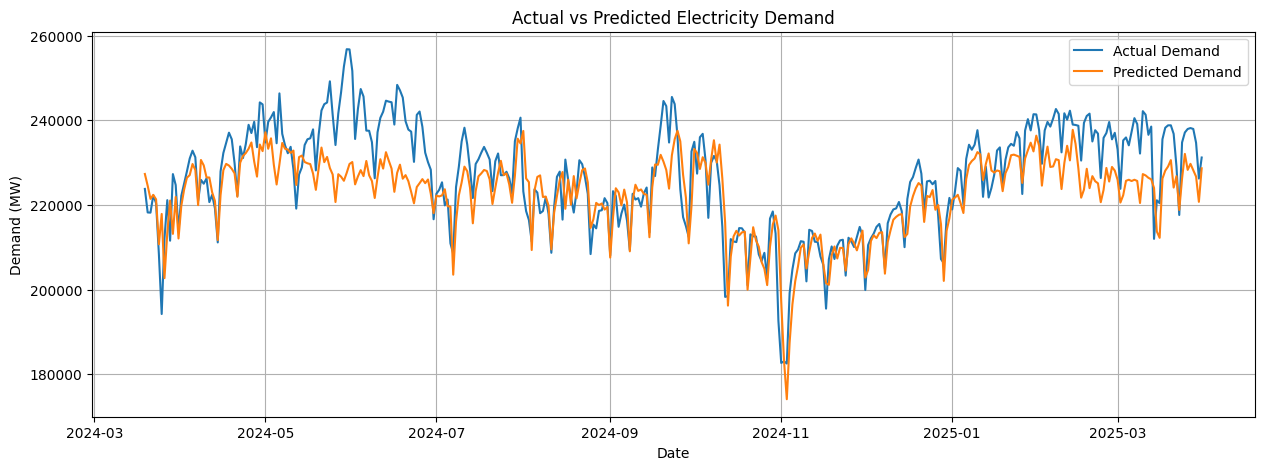

In [89]:
plt.figure(figsize=(15, 5))

plt.plot(
    test_df["Date"],
    y_test,
    label="Actual Demand"
)

plt.plot(
    test_df["Date"],
    y_pred,
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True)
plt.show()

In [90]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("MAE:", round(mae, 2), "MW")
print("RMSE:", round(rmse, 2), "MW")
print("MAPE:", round(mape, 2), "%")

MAE: 6243.22 MW
RMSE: 8132.93 MW
MAPE: 2.71 %


In [107]:

from pathlib import Path
import pandas as pd

results = pd.DataFrame({
    "Model": ["Baseline (lag_30)", "Current ML Model"],
    "MAE_MW": [baseline_mae, mae],
    "RMSE_MW": [baseline_rmse, rmse],
    "MAPE_percent": [None, mape]
})

# Create the reports folder if it doesn't exist
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation results
output_file = reports_dir / "model_evaluation.csv"
results.to_csv(output_file, index=False)

print(results)
print("\nSaved to:", output_file.resolve())


               Model        MAE_MW       RMSE_MW  MAPE_percent
0  Baseline (lag_30)  11631.246032  14840.309917           NaN
1   Current ML Model   6243.215030   8132.925897      2.707051

Saved to: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\model_evaluation.csv


Top 10 features:
lag_1              0.4792
rolling_mean_7     0.2133
rolling_mean_14    0.1835
lag_7              0.0351
day_of_week        0.0195
week_of_year       0.0177
rolling_mean_30    0.0125
day_of_year        0.0109
year               0.0095
lag_14             0.0058
dtype: float32


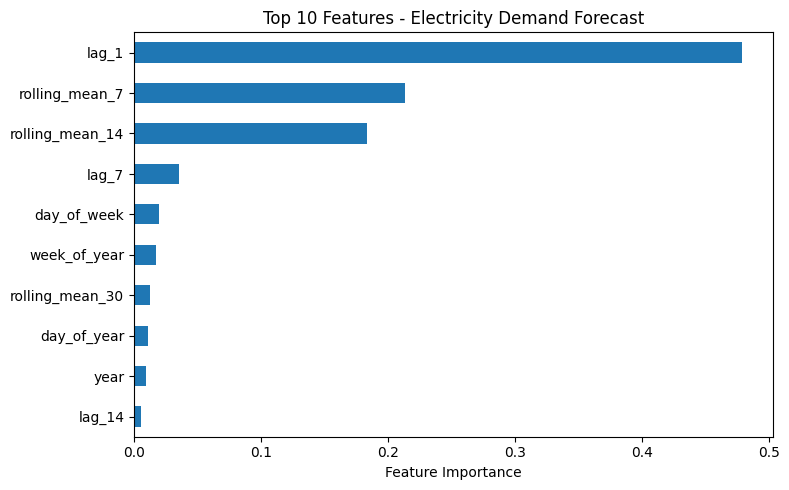

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Display the most influential features
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 features:")
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Features - Electricity Demand Forecast")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


In [94]:

from pathlib import Path
import joblib
import json

# Project folders
project_dir = Path.cwd().parent
models_dir = project_dir / "Models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(model, models_dir / "demand_model.pkl")

# Save the exact feature order expected by the model
with open(models_dir / "demand_features.json", "w") as f:
    json.dump(list(X_train.columns), f, indent=4)

print("Model saved:", models_dir / "demand_model.pkl")
print("Features saved:", models_dir / "demand_features.json")


Model saved: c:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\Models\demand_model.pkl
Features saved: c:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\Models\demand_features.json


In [95]:

from pathlib import Path
import sys

project_dir = Path.cwd().parent
sys.path.insert(0, str(project_dir / "src"))

from predict import predict_demand

sample = X_test.iloc[0].to_dict()

print("Input features:", sample)

result = predict_demand(sample)

print("\nPredicted demand:", result)
print("Actual demand:", float(y_test.iloc[0]), "MW")


Input features: {'year': 2024.0, 'month': 3.0, 'day': 19.0, 'day_of_week': 1.0, 'day_of_year': 79.0, 'week_of_year': 12.0, 'lag_1': 226290.0, 'lag_7': 227328.0, 'lag_14': 219108.0, 'lag_30': 214674.0, 'rolling_mean_7': 225160.2857142857, 'rolling_mean_14': 222719.42857142858, 'rolling_mean_30': 221513.1}

Predicted demand: {'demand_forecast_mw': 227329.34375}
Actual demand: 223797.0 MW


In [97]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Recalculate baseline metrics
baseline_pred = X_test["lag_30"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

# Recalculate current model metrics if needed
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Model MAE:", round(mae, 2))
print("Model RMSE:", round(rmse, 2))


Baseline MAE: 11631.25
Baseline RMSE: 14840.31
Model MAE: 6243.22
Model RMSE: 8132.93


In [98]:

from pathlib import Path
import pandas as pd

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Model": ["Baseline (lag_30)", "Current ML Model"],
    "MAE_MW": [baseline_mae, mae],
    "RMSE_MW": [baseline_rmse, rmse],
    "MAPE_percent": [None, mape]
})

output_file = reports_dir / "model_evaluation.csv"
results.to_csv(output_file, index=False)

print(results)
print("Saved to:", output_file.resolve())


               Model        MAE_MW       RMSE_MW  MAPE_percent
0  Baseline (lag_30)  11631.246032  14840.309917           NaN
1   Current ML Model   6243.215030   8132.925897      2.707051
Saved to: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\model_evaluation.csv


In [99]:

import sys
from pathlib import Path

# Make the src folder importable
project_dir = Path.cwd().parent
sys.path.insert(0, str(project_dir / "src"))

from predict import predict_demand

# Use one real row from your existing test dataset
sample = X_test.iloc[0].to_dict()

result = predict_demand(sample)

print("Prediction interface test:")
print(result)
print("Actual demand:", float(y_test.iloc[0]), "MW")


Prediction interface test:
{'demand_forecast_mw': 227329.34375}
Actual demand: 223797.0 MW


In [100]:

from pathlib import Path

project_dir = Path.cwd().parent
models_dir = project_dir / "Models"

required_files = [
    "demand_model.pkl",
    "demand_features.json"
]

for filename in required_files:
    path = models_dir / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")


demand_model.pkl: FOUND
demand_features.json: FOUND


In [ ]:
# retraining model 
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Features and target
features = [
    "year", "month", "day", "day_of_week",
    "day_of_year", "week_of_year",
    "lag_1", "lag_7", "lag_14", "lag_30",
    "rolling_mean_7", "rolling_mean_14", "rolling_mean_30"
]

X = forecast_df[features]
y = forecast_df["Demand"]

# Chronological split: first 80% train, last 20% test
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train model
model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"MAE: {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")
print(f"MAPE: {mape:.2f}%")

Train rows: 1509
Test rows: 378
MAE: 5193.60 MW
RMSE: 6929.60 MW
MAPE: 2.26%


In [118]:
import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

evaluation = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [mae, rmse, mape],
    "Unit": ["MW", "MW", "%"]
})

evaluation.to_csv(reports_dir / "model_evaluation.csv", index=False)

print(evaluation)
print("\nSaved to:", reports_dir / "model_evaluation.csv")

  Metric        Value Unit
0    MAE  5193.597388   MW
1   RMSE  6929.603931   MW
2   MAPE     2.260522    %

Saved to: ..\reports\model_evaluation.csv


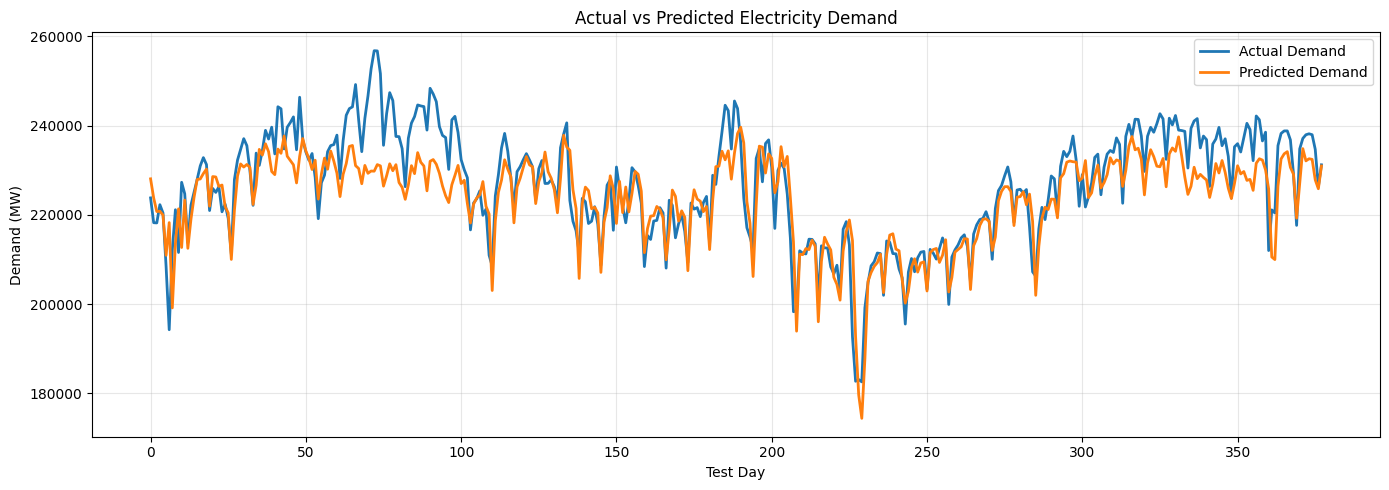

In [119]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.reset_index(drop=True),
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    y_pred,
    label="Predicted Demand",
    linewidth=2
)

plt.title("Actual vs Predicted Electricity Demand")
plt.xlabel("Test Day")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [120]:
baseline_pred = X_test["lag_30"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

mae_improvement = (
    (baseline_mae - mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - rmse) / baseline_rmse
) * 100

print(f"Baseline MAE: {baseline_mae:.2f} MW")
print(f"XGBoost MAE: {mae:.2f} MW")
print(f"MAE improvement: {mae_improvement:.2f}%")

print(f"\nBaseline RMSE: {baseline_rmse:.2f} MW")
print(f"XGBoost RMSE: {rmse:.2f} MW")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

Baseline MAE: 11631.25 MW
XGBoost MAE: 5193.60 MW
MAE improvement: 55.35%

Baseline RMSE: 14840.31 MW
XGBoost RMSE: 6929.60 MW
RMSE improvement: 53.31%


In [123]:
import pandas as pd

renewable_df = pd.read_excel(
    "../Data/January 2024- June 2025.xlsx",
    sheet_name="Report"
)

print("Shape:", renewable_df.shape)
print("\nColumns:")
print(renewable_df.columns.tolist())

print("\nFirst 5 rows:")
display(renewable_df.head())

print("\nData types:")
print(renewable_df.dtypes)

print("\nMissing values:")
print(renewable_df.isnull().sum())

Shape: (12990, 5)

Columns:
['Timestamp', 'Demand (MW)', 'Wind (MW)', 'Solar (MW)', 'Total Generation (MW)']

First 5 rows:


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW)
0,01-01-2024 00:00:00,141981.26,9545.07,20.29,142193.38
1,01-01-2024 01:00:00,138675.49,9027.05,19.96,138792.04
2,01-01-2024 02:00:00,136122.78,8241.48,19.79,136796.02
3,01-01-2024 03:00:00,135806.51,7866.09,19.73,136859.67
4,01-01-2024 04:00:00,139905.77,7430.71,20.02,140561.49



Data types:
Timestamp                object
Demand (MW)              object
Wind (MW)                object
Solar (MW)               object
Total Generation (MW)    object
dtype: object

Missing values:
Timestamp                0
Demand (MW)              0
Wind (MW)                0
Solar (MW)               0
Total Generation (MW)    0
dtype: int64


In [124]:
# Convert columns to correct data types
renewable_df["Timestamp"] = pd.to_datetime(
    renewable_df["Timestamp"],
    format="%d-%m-%Y %H:%M:%S",
    errors="coerce"
)

numeric_cols = [
    "Demand (MW)",
    "Wind (MW)",
    "Solar (MW)",
    "Total Generation (MW)"
]

for col in numeric_cols:
    renewable_df[col] = pd.to_numeric(
        renewable_df[col], errors="coerce"
    )

# Check data quality
print("Data types:")
print(renewable_df.dtypes)

print("\nMissing or invalid values:")
print(renewable_df.isnull().sum())

print("\nDuplicate timestamps:",
      renewable_df["Timestamp"].duplicated().sum())

print("\nDate range:",
      renewable_df["Timestamp"].min(),
      "to",
      renewable_df["Timestamp"].max())

print("\nNegative generation values:")
print((renewable_df[["Wind (MW)", "Solar (MW)"]] < 0).sum())

print("\nTimestamp intervals:")
print(renewable_df["Timestamp"].sort_values().diff().value_counts().head())

Data types:
Timestamp                datetime64[ns]
Demand (MW)                     float64
Wind (MW)                       float64
Solar (MW)                      float64
Total Generation (MW)           float64
dtype: object

Missing or invalid values:
Timestamp                6
Demand (MW)              2
Wind (MW)                2
Solar (MW)               2
Total Generation (MW)    2
dtype: int64

Duplicate timestamps: 5

Date range: 2024-01-01 00:00:00 to 2025-06-24 23:00:00

Negative generation values:
Wind (MW)       0
Solar (MW)    500
dtype: int64

Timestamp intervals:
Timestamp
0 days 01:00:00    12983
Name: count, dtype: int64


In [127]:
# Keep rows with valid timestamps
renewable_df = renewable_df[
    renewable_df["Timestamp"].notna()
].copy()

# Sort chronologically
renewable_df = renewable_df.sort_values("Timestamp").reset_index(drop=True)

print("Shape after removing summary rows:", renewable_df.shape)
print("Missing values:\n", renewable_df.isnull().sum())
print("Duplicate timestamps:", renewable_df["Timestamp"].duplicated().sum())
print("Date range:", renewable_df["Timestamp"].min(), "to", renewable_df["Timestamp"].max())

Shape after removing summary rows: (12984, 5)
Missing values:
 Timestamp                0
Demand (MW)              0
Wind (MW)                0
Solar (MW)               0
Total Generation (MW)    0
dtype: int64
Duplicate timestamps: 0
Date range: 2024-01-01 00:00:00 to 2025-06-24 23:00:00


In [131]:
# Check hourly timestamp continuity
time_diff = renewable_clean["Timestamp"].diff()

print("Hourly intervals:")
print(time_diff.value_counts().head())

print("\nIntervals other than 1 hour:")
print((time_diff != pd.Timedelta(hours=1)).sum() - 1)

print("\nTotal rows:", len(renewable_clean))
print("Unique timestamps:", renewable_clean["Timestamp"].nunique())

Hourly intervals:
Timestamp
0 days 01:00:00    12983
Name: count, dtype: int64

Intervals other than 1 hour:
0

Total rows: 12984
Unique timestamps: 12984


In [132]:
# Create a modeling dataframe
forecast_renewable = renewable_clean.copy()

# Time-based features
forecast_renewable["hour"] = forecast_renewable["Timestamp"].dt.hour
forecast_renewable["day_of_week"] = forecast_renewable["Timestamp"].dt.dayofweek
forecast_renewable["month"] = forecast_renewable["Timestamp"].dt.month
forecast_renewable["day_of_year"] = forecast_renewable["Timestamp"].dt.dayofyear

# Previous-hour generation features
for col in ["Solar (MW)", "Wind (MW)"]:
    forecast_renewable[f"{col}_lag_1"] = forecast_renewable[col].shift(1)
    forecast_renewable[f"{col}_lag_24"] = forecast_renewable[col].shift(24)

# Remove rows without lag values
forecast_renewable = forecast_renewable.dropna().reset_index(drop=True)

print("Modeling dataset shape:", forecast_renewable.shape)
print("\nColumns:")
print(forecast_renewable.columns.tolist())

display(forecast_renewable.head())

Modeling dataset shape: (12960, 13)

Columns:
['Timestamp', 'Demand (MW)', 'Wind (MW)', 'Solar (MW)', 'Total Generation (MW)', 'hour', 'day_of_week', 'month', 'day_of_year', 'Solar (MW)_lag_1', 'Solar (MW)_lag_24', 'Wind (MW)_lag_1', 'Wind (MW)_lag_24']


,Timestamp,Demand (MW),Wind (MW),Solar (MW),Total Generation (MW),hour,day_of_week,month,day_of_year,Solar (MW)_lag_1,Solar (MW)_lag_24,Wind (MW)_lag_1,Wind (MW)_lag_24
0,2024-01-02 00:00:00,142243.14,9010.30,0.0,142945.36,0,1,1,2,0.0,20.29,9255.27,9545.07
1,2024-01-02 01:00:00,138483.54,8503.50,0.0,139276.39,1,1,1,2,0.0,19.96,9010.30,9027.05
2,2024-01-02 02:00:00,135865.51,7583.29,0.0,137112.93,2,1,1,2,0.0,19.79,8503.50,8241.48
3,2024-01-02 03:00:00,135621.46,6827.20,0.0,136574.94,3,1,1,2,0.0,19.73,7583.29,7866.09
4,2024-01-02 04:00:00,139341.82,6523.01,0.0,139988.61,4,1,1,2,0.0,20.02,6827.20,7430.71


In [133]:
from sklearn.model_selection import train_test_split

# Forecasting input features
feature_cols = [
    "hour",
    "day_of_week",
    "month",
    "day_of_year",
    "Solar (MW)_lag_1",
    "Solar (MW)_lag_24",
    "Wind (MW)_lag_1",
    "Wind (MW)_lag_24"
]

X = forecast_renewable[feature_cols]

# Separate targets
y_solar = forecast_renewable["Solar (MW)"]
y_wind = forecast_renewable["Wind (MW)"]

# Chronological split: first 80% train, final 20% test
split_idx = int(len(forecast_renewable) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_solar_train = y_solar.iloc[:split_idx]
y_solar_test = y_solar.iloc[split_idx:]

y_wind_train = y_wind.iloc[:split_idx]
y_wind_test = y_wind.iloc[split_idx:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:",
      forecast_renewable["Timestamp"].iloc[0],
      "to",
      forecast_renewable["Timestamp"].iloc[split_idx - 1])
print("Testing period:",
      forecast_renewable["Timestamp"].iloc[split_idx],
      "to",
      forecast_renewable["Timestamp"].iloc[-1])

Training rows: 10368
Testing rows: 2592
Training period: 2024-01-02 00:00:00 to 2025-03-08 23:00:00
Testing period: 2025-03-09 00:00:00 to 2025-06-24 23:00:00


In [134]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Baseline: use generation from the same hour yesterday
solar_baseline = X_test["Solar (MW)_lag_24"]
wind_baseline = X_test["Wind (MW)_lag_24"]

# Solar metrics
solar_mae = mean_absolute_error(y_solar_test, solar_baseline)
solar_rmse = np.sqrt(mean_squared_error(y_solar_test, solar_baseline))

# Wind metrics
wind_mae = mean_absolute_error(y_wind_test, wind_baseline)
wind_rmse = np.sqrt(mean_squared_error(y_wind_test, wind_baseline))

print("SOLAR BASELINE")
print(f"MAE:  {solar_mae:.2f} MW")
print(f"RMSE: {solar_rmse:.2f} MW")

print("\nWIND BASELINE")
print(f"MAE:  {wind_mae:.2f} MW")
print(f"RMSE: {wind_rmse:.2f} MW")

SOLAR BASELINE
MAE:  1292.58 MW
RMSE: 4262.05 MW

WIND BASELINE
MAE:  2070.59 MW
RMSE: 2709.14 MW


In [135]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Solar model
solar_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

solar_model.fit(X_train, y_solar_train)
solar_pred = solar_model.predict(X_test)

# Wind model
wind_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

wind_model.fit(X_train, y_wind_train)
wind_pred = wind_model.predict(X_test)

# Evaluation
solar_mae_xgb = mean_absolute_error(y_solar_test, solar_pred)
solar_rmse_xgb = np.sqrt(mean_squared_error(y_solar_test, solar_pred))

wind_mae_xgb = mean_absolute_error(y_wind_test, wind_pred)
wind_rmse_xgb = np.sqrt(mean_squared_error(y_wind_test, wind_pred))

print("SOLAR XGBOOST")
print(f"MAE:  {solar_mae_xgb:.2f} MW")
print(f"RMSE: {solar_rmse_xgb:.2f} MW")

print("\nWIND XGBOOST")
print(f"MAE:  {wind_mae_xgb:.2f} MW")
print(f"RMSE: {wind_rmse_xgb:.2f} MW")

SOLAR XGBOOST
MAE:  1037.31 MW
RMSE: 1996.30 MW

WIND XGBOOST
MAE:  568.81 MW
RMSE: 776.99 MW


In [136]:
import joblib
import pandas as pd
from pathlib import Path

# Existing project folders (notebook runs from notebooks/)
models_dir = Path("../Models")
reports_dir = Path("../reports")

models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Save trained models
joblib.dump(solar_model, models_dir / "solar_model.pkl")
joblib.dump(wind_model, models_dir / "wind_model.pkl")

# Save the input feature list
joblib.dump(feature_cols, models_dir / "renewable_features.pkl")

# Save evaluation metrics
metrics = pd.DataFrame([
    {
        "Target": "Solar",
        "Model": "Baseline (lag_24)",
        "MAE_MW": solar_mae,
        "RMSE_MW": solar_rmse
    },
    {
        "Target": "Solar",
        "Model": "XGBoost",
        "MAE_MW": solar_mae_xgb,
        "RMSE_MW": solar_rmse_xgb
    },
    {
        "Target": "Wind",
        "Model": "Baseline (lag_24)",
        "MAE_MW": wind_mae,
        "RMSE_MW": wind_rmse
    },
    {
        "Target": "Wind",
        "Model": "XGBoost",
        "MAE_MW": wind_mae_xgb,
        "RMSE_MW": wind_rmse_xgb
    }
])

metrics.to_csv(
    reports_dir / "renewable_model_evaluation.csv",
    index=False
)

print("Saved solar model:", (models_dir / "solar_model.pkl").resolve())
print("Saved wind model:", (models_dir / "wind_model.pkl").resolve())
print("Saved features:", (models_dir / "renewable_features.pkl").resolve())
print("Saved metrics:", (reports_dir / "renewable_model_evaluation.csv").resolve())
print("\n", metrics.to_string(index=False))

Saved solar model: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\Models\solar_model.pkl
Saved wind model: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\Models\wind_model.pkl
Saved features: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\Models\renewable_features.pkl
Saved metrics: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\renewable_model_evaluation.csv

 Target             Model      MAE_MW     RMSE_MW
 Solar Baseline (lag_24) 1292.584938 4262.052562
 Solar           XGBoost 1037.307220 1996.295436
  Wind Baseline (lag_24) 2070.586181 2709.141060
  Wind           XGBoost  568.806780  776.992144


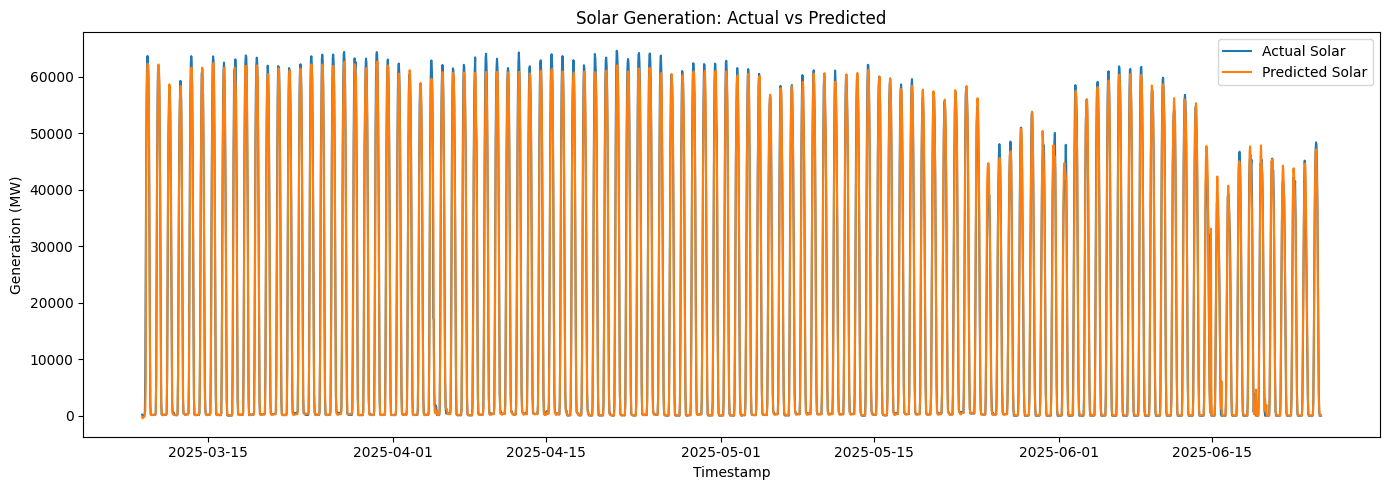

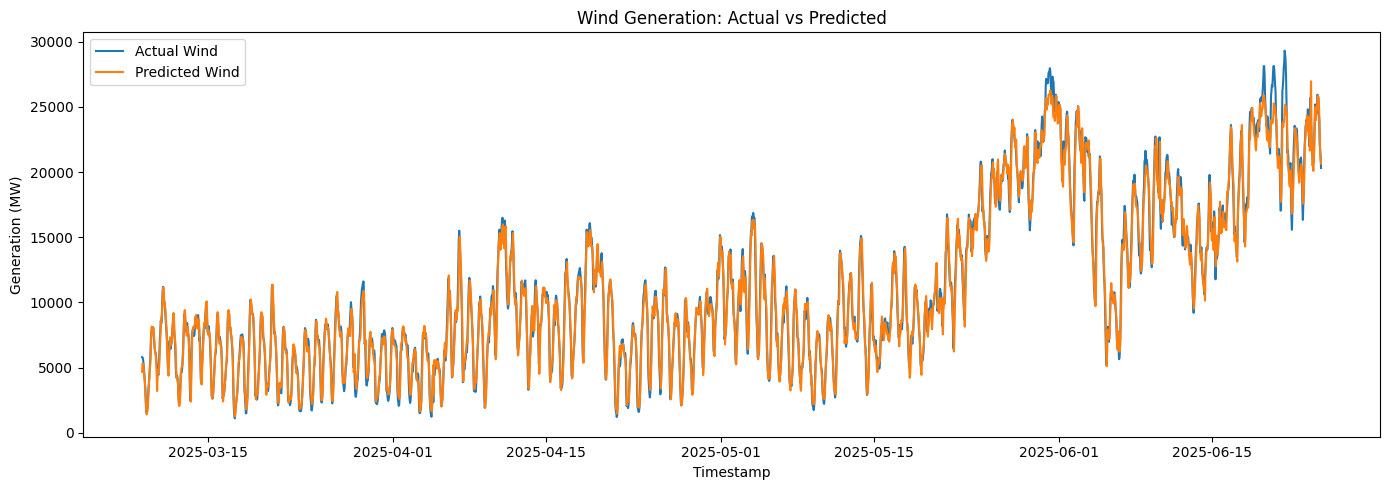

In [137]:
import matplotlib.pyplot as plt

test_dates = forecast_renewable["Timestamp"].iloc[split_idx:]

# Solar plot
plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_solar_test.values, label="Actual Solar")
plt.plot(test_dates, solar_pred, label="Predicted Solar")
plt.title("Solar Generation: Actual vs Predicted")
plt.xlabel("Timestamp")
plt.ylabel("Generation (MW)")
plt.legend()
plt.tight_layout()
plt.show()

# Wind plot
plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_wind_test.values, label="Actual Wind")
plt.plot(test_dates, wind_pred, label="Predicted Wind")
plt.title("Wind Generation: Actual vs Predicted")
plt.xlabel("Timestamp")
plt.ylabel("Generation (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [138]:
# Calculate hourly residual demand and renewable share
renewable_clean["Net Demand (MW)"] = (
    renewable_clean["Demand (MW)"]
    - renewable_clean["Solar (MW)"]
    - renewable_clean["Wind (MW)"]
)

renewable_clean["Renewable Share (%)"] = (
    (
        renewable_clean["Solar (MW)"]
        + renewable_clean["Wind (MW)"]
    )
    / renewable_clean["Demand (MW)"].replace(0, np.nan)
) * 100

print("Net demand summary:")
print(renewable_clean["Net Demand (MW)"].describe())

print("\nRenewable share summary:")
print(renewable_clean["Renewable Share (%)"].describe())

print("\nFirst 5 results:")
display(
    renewable_clean[
        [
            "Timestamp",
            "Demand (MW)",
            "Solar (MW)",
            "Wind (MW)",
            "Net Demand (MW)",
            "Renewable Share (%)"
        ]
    ].head()
)

Net demand summary:
count     12984.000000
mean     169491.759350
std       19493.353768
min       77474.980000
25%      155515.115000
50%      170241.205000
75%      184350.670000
max      218515.530000
Name: Net Demand (MW), dtype: float64

Renewable share summary:
count    12984.000000
mean        12.209484
std          9.227219
min          0.531879
25%          4.541572
50%          8.235190
75%         20.122593
max         40.430405
Name: Renewable Share (%), dtype: float64

First 5 results:


,Timestamp,Demand (MW),Solar (MW),Wind (MW),Net Demand (MW),Renewable Share (%)
0,2024-01-01 00:00:00,141981.26,20.29,9545.07,132415.90,6.737058
1,2024-01-01 01:00:00,138675.49,19.96,9027.05,129628.48,6.523871
2,2024-01-01 02:00:00,136122.78,19.79,8241.48,127861.51,6.068984
3,2024-01-01 03:00:00,135806.51,19.73,7866.09,127920.69,5.806658
4,2024-01-01 04:00:00,139905.77,20.02,7430.71,132455.04,5.325534


In [139]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Save hourly demand and renewable calculations
renewable_clean.to_csv(
    reports_dir / "hourly_renewable_analysis.csv",
    index=False
)

# Save summary statistics
summary = pd.DataFrame({
    "Metric": [
        "Average Net Demand (MW)",
        "Minimum Net Demand (MW)",
        "Maximum Net Demand (MW)",
        "Average Renewable Share (%)",
        "Minimum Renewable Share (%)",
        "Maximum Renewable Share (%)"
    ],
    "Value": [
        renewable_clean["Net Demand (MW)"].mean(),
        renewable_clean["Net Demand (MW)"].min(),
        renewable_clean["Net Demand (MW)"].max(),
        renewable_clean["Renewable Share (%)"].mean(),
        renewable_clean["Renewable Share (%)"].min(),
        renewable_clean["Renewable Share (%)"].max()
    ]
})

summary.to_csv(
    reports_dir / "renewable_analysis_summary.csv",
    index=False
)

print("Saved hourly analysis:",
      (reports_dir / "hourly_renewable_analysis.csv").resolve())
print("Saved summary:",
      (reports_dir / "renewable_analysis_summary.csv").resolve())
print("\n", summary.to_string(index=False))

Saved hourly analysis: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\hourly_renewable_analysis.csv
Saved summary: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\renewable_analysis_summary.csv

                      Metric         Value
    Average Net Demand (MW) 169491.759350
    Minimum Net Demand (MW)  77474.980000
    Maximum Net Demand (MW) 218515.530000
Average Renewable Share (%)     12.209484
Minimum Renewable Share (%)      0.531879
Maximum Renewable Share (%)     40.430405


In [140]:
import joblib
import numpy as np
from pathlib import Path

models_dir = Path("../Models")

# Reload the saved models and feature list
saved_solar_model = joblib.load(models_dir / "solar_model.pkl")
saved_wind_model = joblib.load(models_dir / "wind_model.pkl")
saved_features = joblib.load(models_dir / "renewable_features.pkl")

# Predict using the first test observation
sample = X_test[saved_features].iloc[[0]]

solar_check = saved_solar_model.predict(sample)[0]
wind_check = saved_wind_model.predict(sample)[0]

print("Loaded solar model prediction:", round(float(solar_check), 2), "MW")
print("Loaded wind model prediction:", round(float(wind_check), 2), "MW")
print("Actual solar:", round(float(y_solar_test.iloc[0]), 2), "MW")
print("Actual wind:", round(float(y_wind_test.iloc[0]), 2), "MW")
print("Feature count:", len(saved_features))
print("All predictions finite:", np.isfinite([solar_check, wind_check]).all())

Loaded solar model prediction: -247.6 MW
Loaded wind model prediction: 4679.42 MW
Actual solar: 189.24 MW
Actual wind: 5804.92 MW
Feature count: 8
All predictions finite: True


In [141]:
# Apply a nonnegative floor to solar predictions
solar_pred_corrected = np.maximum(solar_pred, 0)

# Check whether any original predictions were negative
negative_predictions = (solar_pred < 0).sum()

print("Original negative solar predictions:", negative_predictions)
print(
    "Corrected negative solar predictions:",
    (solar_pred_corrected < 0).sum()
)

print(
    "Corrected first solar prediction:",
    round(float(solar_pred_corrected[0]), 2), "MW"
)

Original negative solar predictions: 16
Corrected negative solar predictions: 0
Corrected first solar prediction: 0.0 MW


In [142]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

solar_mae_corrected = mean_absolute_error(
    y_solar_test, solar_pred_corrected
)

solar_rmse_corrected = np.sqrt(
    mean_squared_error(y_solar_test, solar_pred_corrected)
)

print("SOLAR MODEL — ORIGINAL")
print(f"MAE:  {solar_mae_xgb:.2f} MW")
print(f"RMSE: {solar_rmse_xgb:.2f} MW")

print("\nSOLAR MODEL — NONNEGATIVE PREDICTIONS")
print(f"MAE:  {solar_mae_corrected:.2f} MW")
print(f"RMSE: {solar_rmse_corrected:.2f} MW")

print("\nNegative predictions remaining:",
      (solar_pred_corrected < 0).sum())

SOLAR MODEL — ORIGINAL
MAE:  1037.31 MW
RMSE: 1996.30 MW

SOLAR MODEL — NONNEGATIVE PREDICTIONS
MAE:  1036.57 MW
RMSE: 1996.19 MW

Negative predictions remaining: 0


In [143]:
from pathlib import Path
import pandas as pd
import numpy as np

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

prediction_results = pd.DataFrame({
    "Timestamp": forecast_renewable["Timestamp"].iloc[split_idx:].values,
    "Actual Solar (MW)": y_solar_test.values,
    "Predicted Solar (MW)": solar_pred_corrected,
    "Actual Wind (MW)": y_wind_test.values,
    "Predicted Wind (MW)": wind_pred
})

prediction_results.to_csv(
    reports_dir / "renewable_test_predictions.csv",
    index=False
)

print("Saved:", (reports_dir / "renewable_test_predictions.csv").resolve())
print("Rows:", len(prediction_results))
print("\nFirst 5 predictions:")
display(prediction_results.head())

Saved: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\reports\renewable_test_predictions.csv
Rows: 2592

First 5 predictions:


,Timestamp,Actual Solar (MW),Predicted Solar (MW),Actual Wind (MW),Predicted Wind (MW)
0,2025-03-09 00:00:00,189.24,0.0,5804.92,4679.419434
1,2025-03-09 01:00:00,182.50,0.0,5789.10,5310.896973
2,2025-03-09 02:00:00,100.82,0.0,5669.99,5240.943359
3,2025-03-09 03:00:00,103.64,0.0,5358.08,5235.709473
4,2025-03-09 04:00:00,104.32,0.0,4938.52,4740.224609


In [144]:
from pathlib import Path

predict_file = Path("../src/predict.py")
demand_model_file = Path("../Models/demand_model.pkl")
demand_features_file = Path("../Models/demand_features.json")

print("Prediction script exists:", predict_file.exists())
print("Demand model exists:", demand_model_file.exists())
print("Demand feature list exists:", demand_features_file.exists())

if predict_file.exists():
    print("\nPrediction script path:", predict_file.resolve())

Prediction script exists: True
Demand model exists: True
Demand feature list exists: True

Prediction script path: C:\Users\shrey\OneDrive\Documents\MY projects\Energy-Forecasting\src\predict.py


In [145]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../src").resolve()))

from predict import predict_demand

print("Prediction function imported successfully.")

Prediction function imported successfully.


In [152]:
# Select a valid row from the original demand forecasting dataset
valid_row = forecast_df.dropna(subset=demand_features).iloc[-1]

sample_input = valid_row[demand_features].to_dict()

# Test the saved demand prediction interface
result = predict_demand(sample_input)

print("Demand prediction:", result["demand_forecast_mw"], "MW")
print("Actual demand:", float(valid_row["Demand"]), "MW")
print(
    "Absolute error:",
    abs(result["demand_forecast_mw"] - float(valid_row["Demand"])),
    "MW"
)

Demand prediction: 228665.03125 MW
Actual demand: 231218.0 MW
Absolute error: 2552.96875 MW
